In [4]:
import requests
import pandas as pd
url = "https://api.finmindtrade.com/api/v3/data"
parameter = {
    "dataset": "InstitutionalInvestorsBuySell",
    "stock_id": "2330",
    "date": "2020-04-01",
}
data = requests.get(url, params=parameter)
data = data.json()
data = pd.DataFrame(data['data'])


In [5]:
Foreign_Investor = pd.DataFrame(columns=['buy' , 'sell'])
Foreign_Dealer_Self = pd.DataFrame(columns=['buy' , 'sell'])
Investment_Trust = pd.DataFrame(columns=['buy' , 'sell'])
Dealer_self = pd.DataFrame(columns=['buy' , 'sell'])
Dealer_Hedging = pd.DataFrame(columns=['buy' , 'sell'])
for i in data.values:
    match i[3]:
        case 'Foreign_Investor':
            Foreign_Investor.loc[len(Foreign_Investor)] = [i[2],i[4]]
        case 'Foreign_Dealer_Self':
            Foreign_Dealer_Self.loc[len(Foreign_Dealer_Self)] = [i[2],i[4]]
        case 'Investment_Trust':
            Investment_Trust.loc[len(Investment_Trust)] = [i[2],i[4]]
        case 'Dealer_self':
            Dealer_self.loc[len(Dealer_self)] = [i[2],i[4]]
        case 'Dealer_Hedging':
            Dealer_Hedging.loc[len(Dealer_Hedging)] = [i[2],i[4]]
            

In [ ]:
import csv
with open("stock.csv", "w", newline="") as csvfile:
  writer = csv.writer(csvfile)
  writer.writerow(Foreign_Investor)
  writer.writerow(Foreign_Dealer_Self)
  writer.writerow(Investment_Trust)

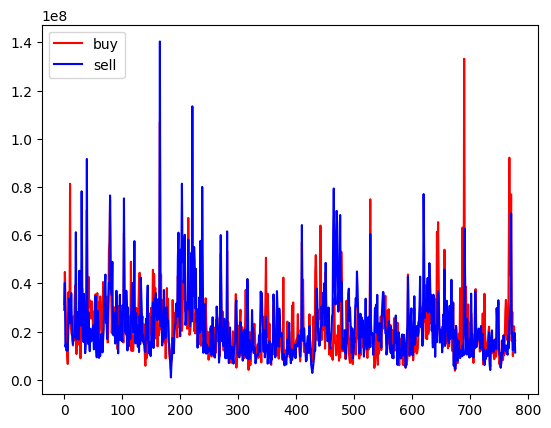

In [6]:

from matplotlib import pyplot

pyplot.plot(Foreign_Investor['buy'] , color = 'red' , label = 'buy')
pyplot.plot(Foreign_Investor['sell'] , color = 'blue' , label = 'sell')

pyplot.legend()